# Coworking Members — Feature Engineering, Lifetime Value & Segmentation

This notebook takes the raw `acdc_dataset.csv` (15,465 coworking members, 31 columns) and:

1. **Cleans** the data (inconsistent labels, hidden missing values, impossible values, mixed date formats).
2. **Engineers features** that describe each member's plan, usage, spending and relationship with the space.
3. **Analyses lifetime value (LTV)** — how it is built, how concentrated it is, and what a new member is worth per plan.
4. **Segments members** with K-means into groups with distinct behaviour, value and churn.

**Target definition used throughout:** a member has *left* (`churned = 1`) when `membership_end` holds a real date.
`membership_end = 1970-01-01` is a placeholder meaning the member is **still active**.
The data snapshot is taken as **2024-01-01**.

## 0. Setup
Libraries, path to the data file and a shared chart style.

In [4]:
%pip install scikit-learn

  Using cached scikit_learn-1.6.1-cp39-cp39-macosx_12_0_arm64.whl (11.1 MB)
  Using cached joblib-1.5.3-py3-none-any.whl (309 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)
You should consider upgrading via the '/Users/fabiana/Faculdade/DM/.venv/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score

DATA_PATH = "acdc_dataset.csv"

PLANS = ["hot_desk", "flex", "full_time", "dedicated_desk", "private_office"]
COLORS = dict(zip(PLANS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold"})

In [2]:
import os
print(os.getcwd())
print(os.listdir())

/Users/fabiana/Faculdade/DM
['Untitled.ipynb', 'acdc_dataset.csv', '.venv', '.ipynb_checkpoints']


## 1. Data cleaning

Problems found during exploration and how `load_clean()` handles them:

| Problem | Example | Treatment |
|---|---|---|
| Exact duplicate rows | 15 rows | dropped |
| Inconsistent labels | `F`, `female`, ` Female` · `PT`, `Portucal` · `hotdesk`, `Hot Desk` | normalised to one label per category |
| `lifetime_value` stored as text | `"390.00 €"`, `"4,311.15"` | parsed to number |
| Mixed date formats | `2021-08-01` vs `01/08/2021` | both formats parsed |
| Sentinel values (hidden missing) | `days_since_last_visit = 999`, `n_colleagues = -1`, industry `Unknown` | converted to `NaN` |
| Impossible values | age 1 or 149, negative visits/hours/renewals, 9 days per week | converted to `NaN` |
| Placeholder end date | `membership_end = 1970-01-01` | flag `has_end_date = False` (active member) |

Two derived columns are also created here because later steps need them: `usage_ratio` (visits used ÷ visits entitled in the last period) and `tenure_days` (days from joining to leaving, or to the snapshot date for active members).

In [5]:
COUNTRY = {"portugal": "Portugal", "portucal": "Portugal", "pt": "Portugal",
           "united kingdom": "United Kingdom", "uk": "United Kingdom", "gb": "United Kingdom", "u.k.": "United Kingdom",
           "germany": "Germany", "de": "Germany", "deutschland": "Germany",
           "spain": "Spain", "es": "Spain", "espana": "Spain", "españa": "Spain",
           "france": "France", "fr": "France", "ireland": "Ireland", "ie": "Ireland",
           "netherlands": "Netherlands", "the netherlands": "Netherlands", "nl": "Netherlands", "holland": "Netherlands",
           "other (europe)": "Other (Europe)"}
PLAN = {"flex": "flex", "hotdesk": "hot_desk", "fulltime": "full_time", "dedicateddesk": "dedicated_desk", "privateoffice": "private_office"}
INDUSTRY = {"it": "information technology", "tech": "information technology", "design/creative": "design & creative",
            "design and creative": "design & creative", "marketing/pr": "marketing & pr", "marketing and pr": "marketing & pr",
            "realestate": "real estate", "real-estate": "real estate"}
SNAPSHOT = pd.Timestamp("2024-01-01")
NON_NEG = ["total_visits", "meeting_room_hours", "event_space_hours", "guest_passes_issued", "n_renewals", "lifetime_value"]


def load_clean(path=DATA_PATH):
    df = pd.read_csv(path, sep=";").drop_duplicates().reset_index(drop=True)
    df["lifetime_value"] = pd.to_numeric(df["lifetime_value"].astype(str).str.replace("€", "").str.replace(",", "").str.strip(), errors="coerce")
    df["gender"] = df["gender"].str.strip().str.lower().str[0].map({"f": "Female", "m": "Male", "o": "Other"})
    df["country"] = df["country"].str.strip().str.lower().map(COUNTRY)
    df["plan_tier"] = df["plan_tier"].str.lower().str.replace(r"[ _]", "", regex=True).map(PLAN)
    ind = df["industry"].str.strip().str.lower()
    df["industry"] = ind.replace(INDUSTRY).replace("unknown", np.nan).str.title().str.replace("& Pr", "& PR")
    for c in ["membership_start", "membership_end", "last_badge_swipe"]:
        iso = pd.to_datetime(df[c], format="%Y-%m-%d", errors="coerce")
        df[c] = iso.fillna(pd.to_datetime(df[c], format="%d/%m/%Y", errors="coerce"))
    df["has_end_date"] = df["membership_end"].dt.year > 1970
    df.loc[~df["has_end_date"], "membership_end"] = pd.NaT
    df.loc[df["days_since_last_visit"] == 999, "days_since_last_visit"] = np.nan
    df.loc[df["days_since_last_visit"] < 0, "days_since_last_visit"] = np.nan
    df.loc[df["n_colleagues_on_account"] == -1, "n_colleagues_on_account"] = np.nan
    df.loc[~df["age"].between(18, 90), "age"] = np.nan
    df.loc[~df["plan_days_per_week"].isin([2, 3, 5, 7]), "plan_days_per_week"] = np.nan
    for c in NON_NEG:
        df.loc[df[c] < 0, c] = np.nan
    df["usage_ratio"] = (df["actual_visits_last_period"] / df["entitled_visits_last_period"].replace(0, np.nan)).clip(upper=1.5)
    end = df["membership_end"].fillna(SNAPSHOT)
    df["tenure_days"] = (end - df["membership_start"]).dt.days
    df.loc[df["tenure_days"] < 0, "tenure_days"] = np.nan
    df.loc[df["total_visits"] > df["tenure_days"].clip(lower=30) / 30.44 * 31, "total_visits"] = np.nan
    return df

In [6]:
df = load_clean()
print(df.shape)
print("Members who left:", df.has_end_date.sum(), f"({df.has_end_date.mean():.0%})")
df[["gender", "country", "plan_tier", "industry"]].nunique()

(15450, 34)
Members who left: 11496 (74%)


gender        3
country       8
plan_tier     5
industry     10
dtype: int64

## 2. Feature engineering

`build_features()` turns the cleaned table into one row per member with features grouped by theme:

| Group | Features | Why |
|---|---|---|
| **Plan** | `plan_tier`, `plan_rank` (1 = hot desk … 5 = private office), `monthly_price` | The plan is the strongest single driver of churn and value. Missing `plan_tier` is recovered from `plan_days_per_week` when it is unambiguous (2, 3 or 7 days). |
| **Time** | `tenure_months`, `start_year`, `start_quarter`, `joined_q4_2023` | Cohort effects; the last cohort has had little time to leave (censoring). |
| **Value** | `ltv_clean`, `expected_ltv`, `ltv_per_month`, `ltv_vs_expected` | LTV corrected for errors; how much a member pays compared with their plan price. |
| **Usage** | `usage_ratio`, `visits_per_week_recent`, `visits_per_month`, `visits_per_plan_day`, `activity_trend` | How much of what they pay for they actually use, and whether usage is rising or falling. |
| **Amenities** | `meeting_hours_per_month`, `event_hours_per_month`, `guest_passes_per_month`, `n_services`, `anchored` | Normalised per month so long-tenure members are not favoured. `anchored` = uses mail handling or storage, i.e. the space is their address or locker. |
| **Loyalty** | `n_renewals`, `renewals_per_year` | Commitment over time. |
| **Account / profile** | `is_team_account`, `team_size`, `age`, `age_group`, `is_portugal`, `country`, `industry`, `gender` | Context; mostly weak signals. |
| **Missing flags** | `ltv_missing`, `meeting_hours_missing`, `guest_passes_missing`, `recency_missing`, `plan_tier_imputed` | Missingness was shown to be non-random for some columns, so it is kept as information. |

### Fixing lifetime value
LTV follows *plan monthly price × months as member* very closely, which makes errors easy to spot:
- **79 values were stored in cents** (≈100× the expected value) → divided by 100.
- **1,742 zeros** belong to normal members with visits and renewals → treated as missing, not as "paid nothing".
- Values still above 5× the plan price per month → set to missing.

> ⚠️ **Leakage:** the list `LEAKAGE` contains features that are computed using the end of the membership (tenure, total visits, renewals, LTV, last visit). They are fine for description and segmentation but must **not** be used to *predict* churn.

In [7]:
PLAN_RANK = {"hot_desk": 1, "flex": 2, "full_time": 3, "dedicated_desk": 4, "private_office": 5}
PLAN_DAYS = {"hot_desk": 2, "flex": 3, "full_time": 5, "dedicated_desk": 5, "private_office": 7}
DAYS_TO_PLAN = {2: "hot_desk", 3: "flex", 7: "private_office"}
SERVICES = ["uses_meeting_rooms", "uses_event_space", "uses_guest_passes", "uses_print", "uses_mail_handling",
            "uses_phone_booths", "uses_day_passes", "uses_storage", "uses_bike_locker"]
PERIOD_WEEKS = 26.09 / 3
LEAKAGE = ["membership_end", "last_badge_swipe", "days_since_last_visit", "tenure_months", "total_visits",
           "n_renewals", "lifetime_value", "ltv_clean", "expected_ltv", "renewals_per_year"]


def fix_lifetime_value(df):
    months = df["tenure_days"] / 30.44
    ltv = df["lifetime_value"].copy()
    ltv[ltv == 0] = np.nan
    price = (ltv / months).groupby(df["plan_tier"]).median()
    ratio = ltv / (df["plan_tier"].map(price) * months)
    cents = (ratio > 20) | (ratio.isna() & (ltv > 30000))
    ltv[cents] = ltv[cents] / 100
    per_month = ltv / months.clip(lower=1)
    ltv[per_month > 5 * df["plan_tier"].map(price).fillna(price.max())] = np.nan
    return ltv, price


def build_features(df=None):
    if df is None:
        df = load_clean()
    f = pd.DataFrame(index=df.index)
    f["member_id"] = df["member_id"]
    f["churned"] = df["has_end_date"].astype(int)

    plan = df["plan_tier"].fillna(df["plan_days_per_week"].map(DAYS_TO_PLAN))
    f["plan_tier"] = plan
    f["plan_rank"] = plan.map(PLAN_RANK)
    f["plan_tier_imputed"] = (df["plan_tier"].isna() & plan.notna()).astype(int)

    f["tenure_months"] = df["tenure_days"] / 30.44
    f["start_year"] = df["membership_start"].dt.year
    f["start_quarter"] = df["membership_start"].dt.quarter
    f["joined_q4_2023"] = (df["membership_start"] >= "2023-10-01").astype(int)

    ltv, price = fix_lifetime_value(df)
    f["monthly_price"] = plan.map(price)
    f["ltv_clean"] = ltv
    f["expected_ltv"] = f["monthly_price"] * f["tenure_months"]
    f["ltv_per_month"] = ltv / f["tenure_months"].replace(0, np.nan)
    f["ltv_vs_expected"] = (ltv / f["expected_ltv"]).clip(upper=5)
    f["ltv_missing"] = ltv.isna().astype(int)

    f["usage_ratio"] = df["usage_ratio"]
    f["visits_per_week_recent"] = df["actual_visits_last_period"] / PERIOD_WEEKS
    f["avg_weekly_visits"] = df["avg_weekly_visits"].clip(upper=7)
    f["activity_trend"] = (f["visits_per_week_recent"] + 0.1) / (f["avg_weekly_visits"] + 0.1)
    f["visits_per_month"] = df["total_visits"] / f["tenure_months"].clip(lower=1)
    f["visits_per_plan_day"] = f["avg_weekly_visits"] / plan.map(PLAN_DAYS)
    f["days_since_last_visit"] = df["days_since_last_visit"]
    f["recency_missing"] = df["days_since_last_visit"].isna().astype(int)

    months = f["tenure_months"].clip(lower=1)
    f["meeting_hours_per_month"] = df["meeting_room_hours"] / months
    f["event_hours_per_month"] = df["event_space_hours"] / months
    f["guest_passes_per_month"] = df["guest_passes_issued"] / months
    f["meeting_hours_missing"] = df["meeting_room_hours"].isna().astype(int)
    f["guest_passes_missing"] = df["guest_passes_issued"].isna().astype(int)

    svc = df[SERVICES].astype(int)
    f["n_services"] = svc.sum(axis=1)
    f["anchored"] = (svc["uses_mail_handling"] | svc["uses_storage"]).astype(int)
    for c in ["uses_mail_handling", "uses_storage", "uses_day_passes", "uses_meeting_rooms"]:
        f[c] = svc[c]

    f["n_renewals"] = df["n_renewals"]
    f["renewals_per_year"] = df["n_renewals"] / (f["tenure_months"] / 12).clip(lower=1)
    f["is_team_account"] = df["is_team_account"].astype(int)
    f["team_size"] = df["n_colleagues_on_account"] + 1

    f["age"] = df["age"]
    f["age_group"] = pd.cut(df["age"], [17, 25, 35, 45, 55, 90], labels=["18-25", "26-35", "36-45", "46-55", "56+"])
    f["is_portugal"] = (df["country"] == "Portugal").astype(int)
    f["country"] = df["country"]
    f["industry"] = df["industry"]
    f["gender"] = df["gender"]
    f["total_visits"] = df["total_visits"]
    return f

In [8]:
f = build_features(df)
f.to_csv("features_engineered.csv", index=False)
print(f.shape)
f.head()

(15450, 45)


,member_id,churned,plan_tier,plan_rank,plan_tier_imputed,tenure_months,start_year,start_quarter,joined_q4_2023,monthly_price,...,renewals_per_year,is_team_account,team_size,age,age_group,is_portugal,country,industry,gender,total_visits
0,CW000001,1,flex,2.0,0,19.119580,2021,3,0,204.742752,...,1.255258,0,1.0,38.0,36-45,1,Portugal,Information Technology,Female,220.0
1,CW000002,0,hot_desk,1.0,0,1.248357,2023,4,1,131.621665,...,0.000000,1,3.0,38.0,36-45,1,Portugal,Information Technology,Male,2.0
2,CW000003,0,flex,2.0,0,24.934297,2021,4,0,204.742752,...,0.481265,1,2.0,43.0,36-45,0,Germany,Education,Male,19.0
3,CW000004,1,flex,2.0,0,1.445466,2022,1,0,204.742752,...,0.000000,0,1.0,38.0,36-45,1,Portugal,Legal,Female,8.0
4,CW000005,0,hot_desk,1.0,0,2.266754,2023,4,1,131.621665,...,0.000000,0,1.0,45.0,36-45,0,United Kingdom,Information Technology,Female,4.0


### Which engineered features separate active members from those who left?
Spearman correlation of each feature with `churned` (positive = higher values among members who left).

In [9]:
check = ["plan_rank", "usage_ratio", "visits_per_week_recent", "visits_per_plan_day", "anchored",
         "renewals_per_year", "ltv_per_month", "activity_trend", "n_services", "team_size"]
signal = pd.DataFrame({
    "spearman_vs_churn": [f[[c, "churned"]].dropna().corr(method="spearman").iloc[0, 1] for c in check],
    "median_active": [f.loc[f.churned == 0, c].median() for c in check],
    "median_left": [f.loc[f.churned == 1, c].median() for c in check],
}, index=check).round(3).sort_values("spearman_vs_churn", key=abs, ascending=False)
print("Share who left — anchored vs not:", f.groupby("anchored").churned.mean().round(3).to_dict())
signal

Share who left — anchored vs not: {0: 0.818, 1: 0.579}


,spearman_vs_churn,median_active,median_left
visits_per_week_recent,0.318,0.460,1.495
plan_rank,-0.297,3.000,2.000
usage_ratio,0.266,0.232,0.575
visits_per_plan_day,0.263,0.260,0.605
anchored,-0.252,1.000,0.000
renewals_per_year,-0.222,0.801,0.000
ltv_per_month,-0.210,289.981,191.907
activity_trend,0.141,0.909,0.968
n_services,-0.022,2.000,1.000
team_size,0.013,1.000,1.000


**Reading the table:** higher plan tiers, being *anchored* (mail/storage) and renewing often go with staying.
Surprisingly, members who left **used the space more** (higher `usage_ratio` and recent visits). Section 4 explains why: the most loyal group barely visits.

## 3. Lifetime value

### 3.1 How LTV is built
Each dot is a member. The x-axis is the LTV we would expect from *plan price × months*; the y-axis is the recorded LTV.
Points on the dashed line pay exactly their plan. Points above it paid for extras (meeting rooms, guest passes, services).

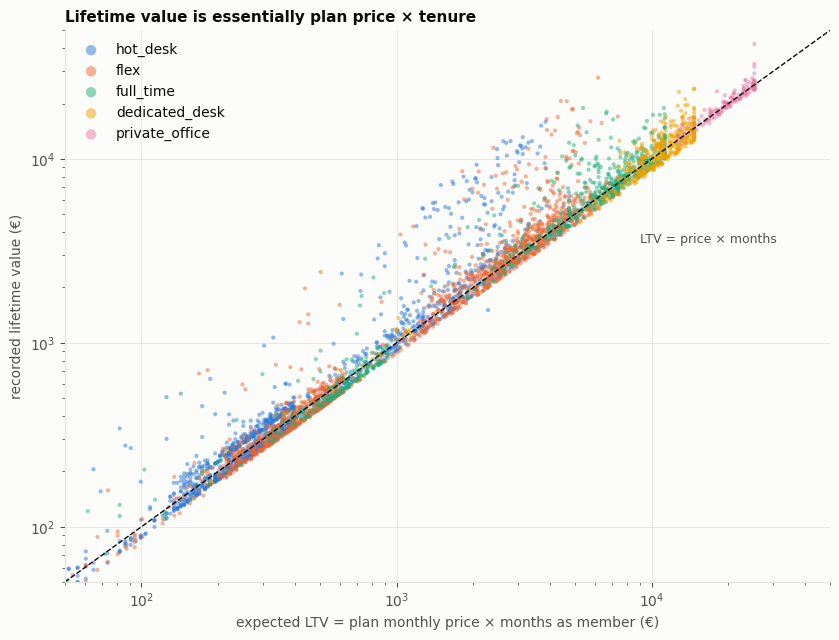

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 6.5))
for p in PLANS:
    d = f[(f.plan_tier == p) & f.ltv_clean.notna() & (f.expected_ltv > 0)].sample(frac=0.35, random_state=0)
    ax.scatter(d.expected_ltv, d.ltv_clean, s=9, color=COLORS[p], alpha=0.5, label=p, edgecolors="none")
lim = [50, 50000]
ax.plot(lim, lim, color=INK, lw=1, ls="--")
ax.text(9000, 3500, "LTV = price × months", color=INK2, fontsize=9, ha="left")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("expected LTV = plan monthly price × months as member (€)"); ax.set_ylabel("recorded lifetime value (€)")
ax.set_title("Lifetime value is essentially plan price × tenure", loc="left")
ax.legend(frameon=False, markerscale=2.5, loc="upper left")
fig.tight_layout(); fig.savefig("7_ltv_formula.png", dpi=130); plt.show()

**Takeaway:** about 62% of members are within ±25% of plan price × tenure, so LTV is mainly a function of **which plan** and **how long**.
Members above the line use more services: someone using 7 services pays about 1.45× their plan.

### 3.2 How concentrated is revenue?
**Left:** members ordered from highest to lowest LTV against the cumulative share of total revenue (a Lorenz-style curve). The further the curve bows above the diagonal, the more concentrated revenue is. The **Gini coefficient** summarises this (0 = everyone pays the same, 1 = one member pays everything).
**Right:** each plan's share of members compared with its share of revenue.

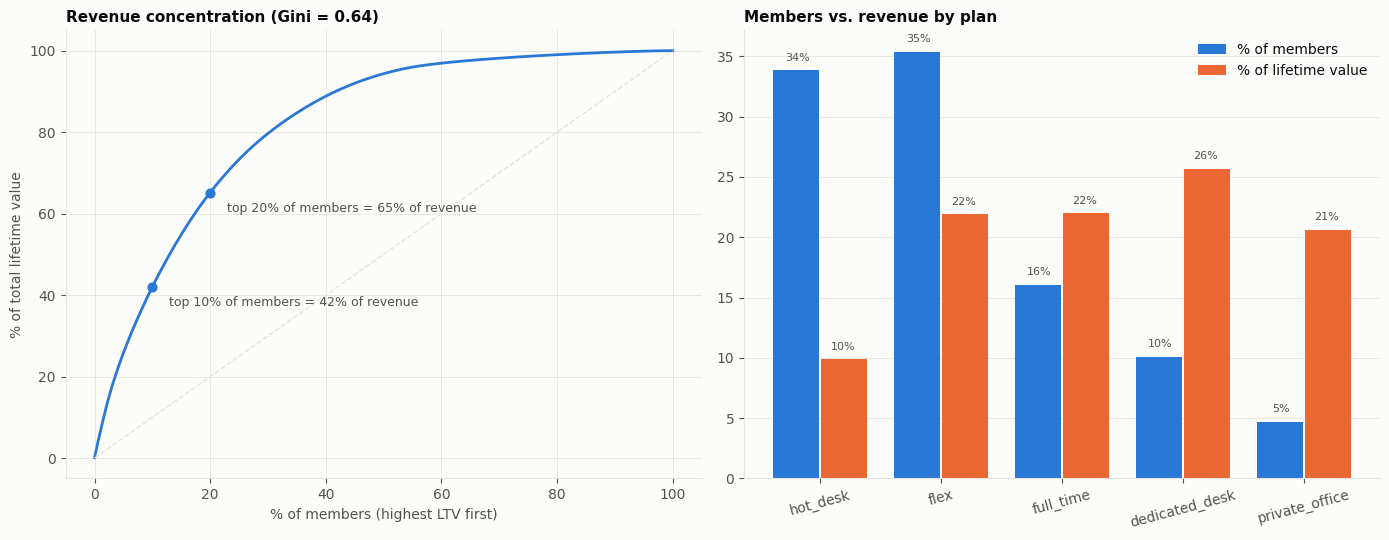

In [11]:
ltv = f.ltv_clean.dropna().sort_values(ascending=False)
share = ltv.cumsum() / ltv.sum()
pct = np.arange(1, len(ltv) + 1) / len(ltv)
x = np.sort(ltv.values); n = len(x)
gini = (2 * np.sum(np.arange(1, n + 1) * x) / (n * x.sum())) - (n + 1) / n
top10, top20 = share.iloc[int(0.1 * n) - 1], share.iloc[int(0.2 * n) - 1]
by_plan = f.groupby("plan_tier").agg(members=("member_id", "size"), revenue=("ltv_clean", "sum")).reindex(PLANS)
by_plan["member_share"] = by_plan.members / by_plan.members.sum()
by_plan["revenue_share"] = by_plan.revenue / by_plan.revenue.sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].plot(pct * 100, share.values * 100, color="#2a78d6", lw=2)
axes[0].plot([0, 100], [0, 100], color=GRID, lw=1, ls="--")
for p_, s_ in [(10, top10), (20, top20)]:
    axes[0].scatter([p_], [s_ * 100], color="#2a78d6", s=40, zorder=3)
    axes[0].annotate(f"top {p_}% of members = {s_:.0%} of revenue", (p_, s_ * 100), xytext=(12, -14), textcoords="offset points", fontsize=9, color=INK2)
axes[0].set_xlabel("% of members (highest LTV first)"); axes[0].set_ylabel("% of total lifetime value")
axes[0].set_title(f"Revenue concentration (Gini = {gini:.2f})", loc="left")
w = 0.38; xs = np.arange(len(PLANS))
axes[1].bar(xs - w / 2 - 0.01, by_plan.member_share * 100, w, color="#2a78d6", label="% of members")
axes[1].bar(xs + w / 2 + 0.01, by_plan.revenue_share * 100, w, color="#eb6834", label="% of lifetime value")
for i, (a, b) in enumerate(zip(by_plan.member_share, by_plan.revenue_share)):
    axes[1].text(i - w / 2, a * 100 + 0.8, f"{a:.0%}", ha="center", fontsize=8, color=INK2)
    axes[1].text(i + w / 2, b * 100 + 0.8, f"{b:.0%}", ha="center", fontsize=8, color=INK2)
axes[1].set_xticks(xs, PLANS, rotation=15); axes[1].grid(axis="x", visible=False)
axes[1].legend(frameon=False); axes[1].set_title("Members vs. revenue by plan", loc="left")
fig.tight_layout(); fig.savefig("8_ltv_concentration.png", dpi=130); plt.show()

**Takeaway:** revenue is highly concentrated (Gini ≈ 0.64). The top 20% of members generate about 65% of lifetime value.
Dedicated desks and private offices are only ~15% of members but bring ~46% of revenue, while hot desks are a third of members and only ~10% of revenue.

### 3.3 Retention and the expected value of a new member
**Left:** Kaplan–Meier retention curves, i.e. the share of members still active *X* months after joining. This method correctly handles active members, whose final tenure is not yet known (censoring).
**Right:** expected 3-year LTV of a new member = *average months retained within 36 months* (area under the curve) × *monthly plan price*.

In [12]:
HORIZON = 36


def kaplan_meier(t, e):
    d = pd.DataFrame({"t": t, "e": e}).dropna().sort_values("t")
    times = np.sort(d.loc[d.e == 1, "t"].unique())
    n_at_risk = np.array([(d.t >= x).sum() for x in times])
    deaths = d.loc[d.e == 1].groupby("t").size().reindex(times).values
    s = np.cumprod(1 - deaths / n_at_risk)
    return np.r_[0, times], np.r_[1, s]


def restricted_mean(times, surv, horizon):
    keep = times <= horizon
    t, s = np.r_[times[keep], horizon], np.r_[surv[keep], surv[keep][-1]]
    return float(np.sum(np.diff(t) * s[:-1]))


def median_survival(times, surv):
    below = np.where(surv <= 0.5)[0]
    return float(times[below[0]]) if len(below) else np.nan

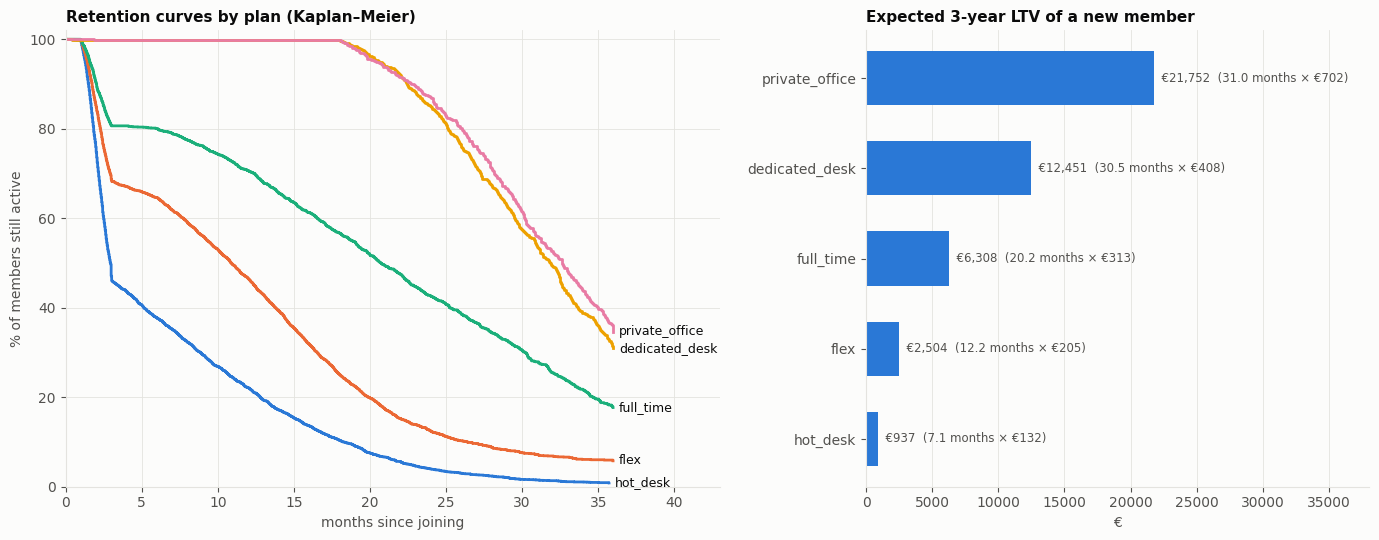

In [13]:
rows = []
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
for p in PLANS:
    d = f[f.plan_tier == p]
    t, s = kaplan_meier(d.tenure_months, d.churned)
    axes[0].step(t, s * 100, where="post", color=COLORS[p], lw=2)
    keep = t <= HORIZON
    axes[0].text(min(t[keep][-1], HORIZON) + 0.4, s[keep][-1] * 100, p, color=INK, fontsize=9, va="center")
    rm = restricted_mean(t, s, HORIZON)
    price = d.monthly_price.iloc[0]
    rows.append((p, len(d), price, median_survival(t, s), rm, rm * price, d.ltv_clean.median()))
axes[0].set_xlim(0, HORIZON + 7); axes[0].set_ylim(0, 102)
axes[0].set_xlabel("months since joining"); axes[0].set_ylabel("% of members still active")
axes[0].set_title("Retention curves by plan (Kaplan–Meier)", loc="left")
res = pd.DataFrame(rows, columns=["plan", "members", "monthly_price", "median_lifetime_m", "expected_lifetime_m_36",
                                  "expected_ltv_new_member", "observed_median_ltv"]).set_index("plan")
axes[1].barh(PLANS, res.expected_ltv_new_member, color="#2a78d6", height=0.6)
for i, p in enumerate(PLANS):
    r = res.loc[p]
    axes[1].text(r.expected_ltv_new_member, i, f"  €{r.expected_ltv_new_member:,.0f}  ({r.expected_lifetime_m_36:.1f} months × €{r.monthly_price:.0f})",
                 va="center", fontsize=8.5, color=INK2)
axes[1].set_xlim(0, res.expected_ltv_new_member.max() * 1.75); axes[1].grid(axis="y", visible=False)
axes[1].set_xlabel("€"); axes[1].set_title("Expected 3-year LTV of a new member", loc="left")
fig.tight_layout(); fig.savefig("9_ltv_survival.png", dpi=130); plt.show()

In [14]:
res.round(1)

,members,monthly_price,median_lifetime_m,expected_lifetime_m_36,expected_ltv_new_member,observed_median_ltv
plan,,,,,,
hot_desk,5212,131.6,3.0,7.1,936.8,349.8
flex,5449,204.7,10.9,12.2,2504.0,1818.9
full_time,2471,312.7,20.7,20.2,6308.1,5794.6
dedicated_desk,1549,407.8,31.8,30.5,12451.5,11004.8
private_office,720,702.1,32.6,31.0,21751.8,21363.3


**Takeaway:**
- Half of hot-desk members leave within **3 months**; flex members last about 11 months.
- Dedicated desks and private offices lose **nobody for the first 18 months**, which suggests an 18-month minimum contract.
- A new member is worth roughly **€940 (hot desk)** up to **€21,750 (private office)** over three years.

## 4. Segmentation

### 4.1 Method
- **Algorithm:** K-means on 9 behavioural features: plan tier, tenure, usage ratio, recent weekly visits, number of services, anchored, meeting hours/month, guest passes/month and LTV vs. plan price.
- **Preparation:** skewed variables are log-transformed (`log1p`), missing values are filled with the median, and all features are standardised (mean 0, sd 1) so that no feature dominates because of its scale.
- Churn is **not** used to build the segments; it is only compared afterwards.

In [15]:
DIV = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#f0efec", "#ef9a99", "#b8302f"])
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]

FEATURES = ["plan_rank", "tenure_months", "usage_ratio", "visits_per_week_recent", "n_services", "anchored",
            "meeting_hours_per_month", "guest_passes_per_month", "ltv_vs_expected"]
LOG = ["meeting_hours_per_month", "guest_passes_per_month", "tenure_months"]
K = 5
SEED = 0


def prepare(f):
    X = f[FEATURES].copy()
    for c in LOG:
        X[c] = np.log1p(X[c].clip(lower=0))
    X = X.fillna(X.median())
    return StandardScaler().fit_transform(X)


def name_segments(p):
    names = {}
    names[p.usage.idxmin()] = "Silent anchors"
    names[p.ltv_ratio.idxmax()] = "Meeting-room power users"
    rest = p.drop(index=list(names))
    names[rest.plan_rank.idxmax()] = "Committed residents"
    rest = rest.drop(index=rest.plan_rank.idxmax())
    names[rest.tenure.idxmin()] = "Short-lived triers"
    names[rest.tenure.idxmax()] = "Engaged flexers"
    return names

### 4.2 Choosing the number of segments (k)
Three criteria for k = 2…8:
- **Inertia (elbow):** within-cluster spread; look for where the curve stops dropping steeply.
- **Silhouette:** how well each member fits its own cluster compared with the next one (higher is better).
- **Davies–Bouldin:** average similarity between clusters (lower is better).

In [17]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

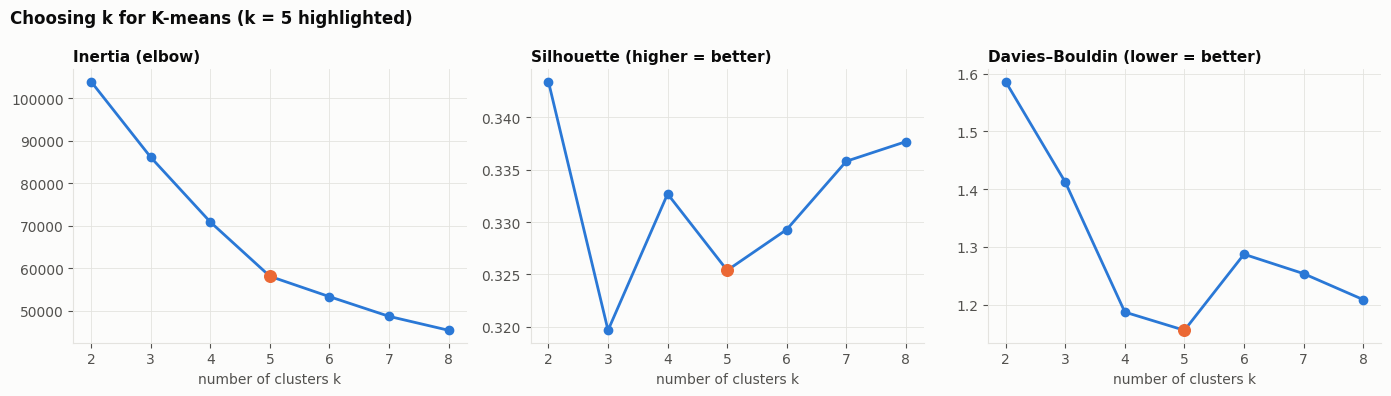

In [18]:
Z = prepare(f)
sample = np.random.RandomState(SEED).choice(len(Z), 5000, replace=False)

ks, inertia, sil, db = range(2, 9), [], [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=SEED).fit(Z)
    inertia.append(km.inertia_); sil.append(silhouette_score(Z[sample], km.labels_[sample])); db.append(davies_bouldin_score(Z, km.labels_))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, vals, title in zip(axes, [inertia, sil, db], ["Inertia (elbow)", "Silhouette (higher = better)", "Davies–Bouldin (lower = better)"]):
    ax.plot(list(ks), vals, color=PALETTE[0], lw=2, marker="o", ms=6)
    ax.scatter([K], [vals[K - 2]], color=PALETTE[1], s=70, zorder=3)
    ax.set_title(title, loc="left"); ax.set_xlabel("number of clusters k")
fig.suptitle(f"Choosing k for K-means (k = {K} highlighted)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig("10_k_selection.png", dpi=130); plt.show()

**Choice: k = 5.** It has the best (lowest) Davies–Bouldin score, sits near the elbow, and gives segments that are easy to interpret.
The silhouette is moderate (~0.33) for every k, so the segments overlap somewhat. That is normal for behavioural data, but it should be mentioned as a limitation.

### 4.3 Fitting the model and naming the segments
Segments are named automatically from their profile (lowest usage, highest extra spend, highest plan tier, shortest and longest tenure).

In [19]:
km = KMeans(K, n_init=10, random_state=SEED).fit(Z)
f["segment_id"] = km.labels_
p = f.groupby("segment_id").agg(members=("member_id", "size"), churn=("churned", "mean"), plan_rank=("plan_rank", "mean"),
                                tenure=("tenure_months", "median"), usage=("usage_ratio", "median"),
                                ltv_ratio=("ltv_vs_expected", "median"), ltv_sum=("ltv_clean", "sum"))
names = name_segments(p)
f["segment"] = f.segment_id.map(names)
order = ["Committed residents", "Silent anchors", "Meeting-room power users", "Engaged flexers", "Short-lived triers"]
colors = dict(zip(order, PALETTE))
f.segment.value_counts()

segment
Short-lived triers          5335
Engaged flexers             4818
Committed residents         2223
Silent anchors              2055
Meeting-room power users    1019
Name: count, dtype: int64

### 4.4 Visualising the segments
Principal Component Analysis (PCA) compresses the 9 features into 2 dimensions so the segments can be plotted. Each dot is a member (random sample of 5,000).
Some segments overlap in this 2-D view (for example *Silent anchors* and *Engaged flexers*) even though they differ strongly on features such as usage, which PCA flattens.

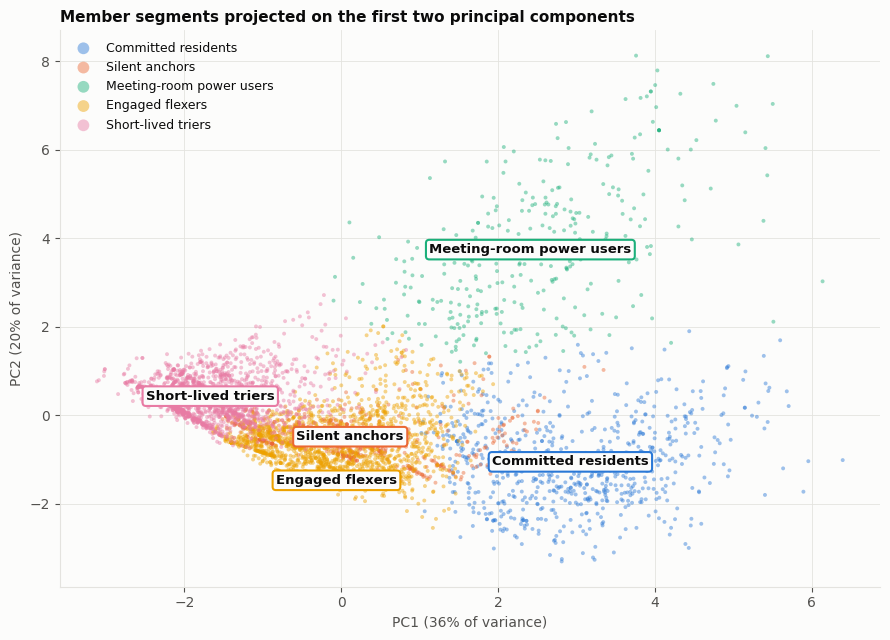

In [20]:
pcs = PCA(2, random_state=SEED).fit(Z)
P = pcs.transform(Z)
fig, ax = plt.subplots(figsize=(9, 6.5))
for s in order:
    m = (f.segment == s).values & np.isin(np.arange(len(f)), sample)
    ax.scatter(P[m, 0], P[m, 1], s=8, alpha=0.45, color=colors[s], edgecolors="none", label=s)
placed = []
for s in order:
    c = P[(f.segment == s).values].mean(axis=0)
    while any(np.hypot(*(c - q)) < 0.8 for q in placed):
        c = c + np.array([0, -0.9])
    placed.append(c)
    ax.text(c[0], c[1], s, fontsize=9.5, fontweight="bold", ha="center", va="center", color=INK,
            bbox={"boxstyle": "round,pad=0.25", "fc": SURF, "ec": colors[s], "lw": 1.5})
ev = pcs.explained_variance_ratio_
ax.set_xlabel(f"PC1 ({ev[0]:.0%} of variance)"); ax.set_ylabel(f"PC2 ({ev[1]:.0%} of variance)")
ax.legend(frameon=False, markerscale=3, loc="best", fontsize=9)
ax.set_title("Member segments projected on the first two principal components", loc="left")
fig.tight_layout(); fig.savefig("11_segments_pca.png", dpi=130); plt.show()

### 4.5 Segment profiles
Each cell shows the segment's value for a feature. The colour shows whether it is **above (red)** or **below (blue)** the average segment.

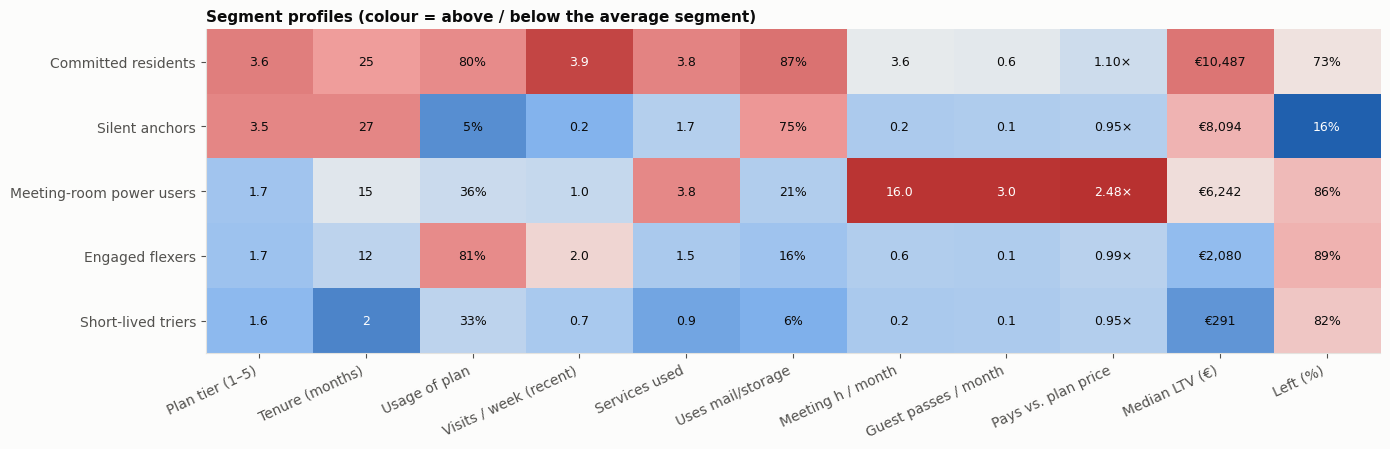

In [21]:
show = {"plan_rank": ("Plan tier (1–5)", "{:.1f}", "mean"), "tenure_months": ("Tenure (months)", "{:.0f}", "median"),
        "usage_ratio": ("Usage of plan", "{:.0%}", "median"), "visits_per_week_recent": ("Visits / week (recent)", "{:.1f}", "median"),
        "n_services": ("Services used", "{:.1f}", "mean"), "anchored": ("Uses mail/storage", "{:.0%}", "mean"),
        "meeting_hours_per_month": ("Meeting h / month", "{:.1f}", "mean"), "guest_passes_per_month": ("Guest passes / month", "{:.1f}", "mean"),
        "ltv_vs_expected": ("Pays vs. plan price", "{:.2f}×", "median"), "ltv_clean": ("Median LTV (€)", "€{:,.0f}", "median"),
        "churned": ("Left (%)", "{:.0%}", "mean")}
raw = pd.DataFrame({k: f.groupby("segment")[k].agg(v[2]) for k, v in show.items()}).reindex(order)
zs = (raw - raw.mean()) / raw.std()
fig, ax = plt.subplots(figsize=(14, 4.6))
ax.imshow(zs.values, cmap=DIV, vmin=-1.8, vmax=1.8, aspect="auto"); ax.grid(False)
ax.set_xticks(range(len(show)), [v[0] for v in show.values()], rotation=25, ha="right")
ax.set_yticks(range(len(order)), order)
for i in range(raw.shape[0]):
    for j, (k, v) in enumerate(show.items()):
        ax.text(j, i, v[1].format(raw.iloc[i, j]), ha="center", va="center", fontsize=9,
                color="white" if abs(zs.iloc[i, j]) > 1.3 else INK)
ax.set_title("Segment profiles (colour = above / below the average segment)", loc="left")
fig.tight_layout(); fig.savefig("12_segment_profiles.png", dpi=130); plt.show()

### 4.6 Size, value and churn of each segment

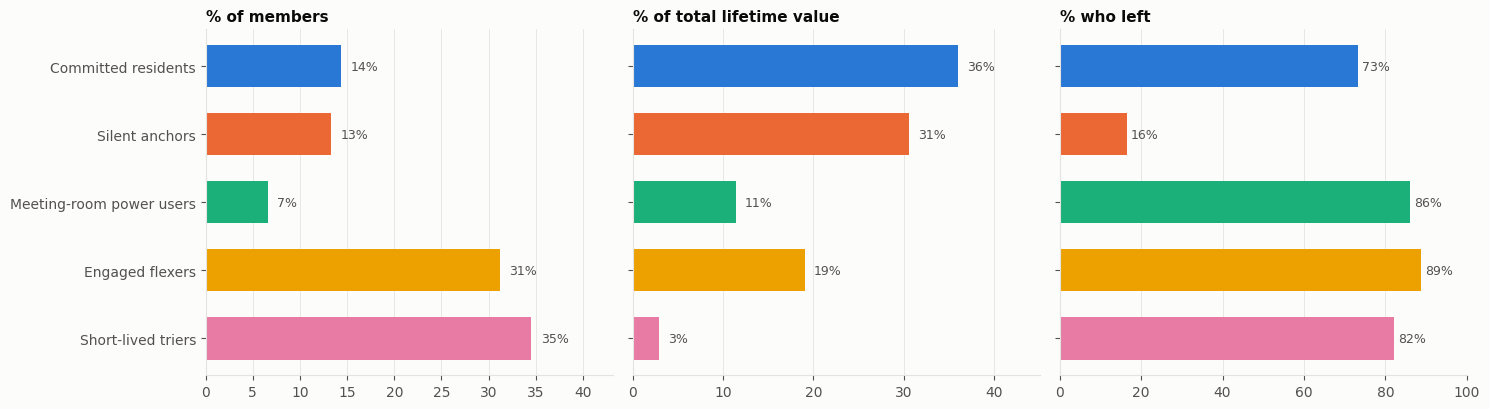

In [22]:
ov = f.groupby("segment").agg(members=("member_id", "size"), churn=("churned", "mean"), ltv=("ltv_clean", "sum")).reindex(order)
ov["member_share"] = ov.members / ov.members.sum(); ov["ltv_share"] = ov.ltv / ov.ltv.sum()
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, col, title in zip(axes, ["member_share", "ltv_share", "churn"], ["% of members", "% of total lifetime value", "% who left"]):
    ax.barh(order[::-1], ov[col][::-1] * 100, color=[colors[s] for s in order[::-1]], height=0.62)
    for y, v in enumerate(ov[col][::-1]):
        ax.text(v * 100 + 1, y, f"{v:.0%}", va="center", fontsize=9, color=INK2)
    ax.set_xlim(0, 100 if col == "churn" else ov[col].max() * 100 * 1.25); ax.set_title(title, loc="left"); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig("13_segment_overview.png", dpi=130); plt.show()

ov[['members', 'member_share', 'ltv_share', 'churn']].round(3)

### 4.7 Segment descriptions

| Segment | Members | Revenue | Left | Who they are |
|---|---|---|---|---|
| **Committed residents** | 14% | 36% | 73% | Dedicated desks, full-time and private offices. Come ~4×/week, use many services, stay ~2 years. The most valuable group. |
| **Silent anchors** | 13% | 31% | **16%** | Premium plans and mail/storage users who **almost never come in** (~5% of their entitlement). They use the space as an address or locker and are by far the most loyal. |
| **Meeting-room power users** | 7% | 11% | 86% | Cheap plans (hot desk/flex) but heavy use of meeting rooms and guest passes: they pay ~2.5× their plan in extras. |
| **Engaged flexers** | 31% | 19% | 89% | Hot desk/flex members who use most of what they pay for (81%), then leave after about a year. |
| **Short-lived triers** | 35% | 3% | 82% | Join, use little, and leave after ~2 months. Large in number, tiny in value. |

## 5. Conclusions

1. **Lifetime value ≈ plan price × tenure.** Increasing value means moving members to higher plans and keeping them longer; extras add on top.
2. **Revenue is concentrated.** The top 20% of members bring ~65% of revenue, mostly from premium plans.
3. **Retention depends on the plan.** Hot desk loses half its members in 3 months, while premium plans appear to have an 18-month commitment.
4. **Churn is driven by the type of relationship, not by how often members visit.** The most loyal segment (*Silent anchors*) barely visits but relies on mail and storage. Active users on flexible plans (*Engaged flexers*) leave the most.
5. **Practical idea:** offering anchoring services (mail handling, storage) to flexible-plan members could be a retention lever worth testing.

**Limitations:** the segments overlap (silhouette ≈ 0.33); tenure-based features leak the outcome and must not be used for churn prediction; the most recent cohort is censored.